## Imports & Initialization:

In [94]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json
from knowledge_maze.evaluation.llm_judge_annotation.judge_annotation import JudgeDatasetManager, JudgeAuditTagger

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Get Annotation Subsets:

In [230]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
mistral_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))

deepseek_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
google_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
meta_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

deepseek_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/deepseek_deepseek-v4-flash.json"))
google_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/google_gemini-3-flash-preview.json"))
meta_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/meta-llama_llama-4-maverick.json"))

deepseek_v4_pro_res = load_json(os.path.join(REPO_PATH, "results/scaling/deepseek_deepseek-v4-pro.json"))
gpt_5_4_res = load_json(os.path.join(REPO_PATH, "results/scaling/openai_gpt-5.4.json"))

In [231]:
experiment_data_map = {
    "main": {
        "Deepseek V4 Flash": deepseek_baseline_res,
        "Gemini 3 Flash": google_baseline_res,
        "Llama 4 Maverick": meta_baseline_res,
        "GPT 5.4 Mini": gpt_baseline_res,
        "Mistral Medium 3.1": mistral_baseline_res,
    },
    "cot": {
        "Deepseek V4 Flash": deepseek_cot_res,
        "Gemini 3 Flash": google_cot_res,
        "Llama 4 Maverick": meta_cot_res,
    },
    "hedge": {
        "Deepseek V4 Flash": deepseek_hedged_res,
        "Gemini 3 Flash": google_hedged_res,
        "Llama 4 Maverick": meta_hedged_res,
    },
    "scaling": {
        "Deepseek V4 Pro": deepseek_v4_pro_res,
        "GPT 5.4": gpt_5_4_res,
    },
}

In [233]:
# Instantiate the complete pipeline module
manager = JudgeDatasetManager(experiment_data_map)

# Step 1: Create your unified golden-proportions target pool (e.g., N=400)
validation_pool = manager.create_validation_set(total_target=400)

# Step 2: Split among 4 annotators with a guaranteed overlap of 33 items for EVERY pair combination
annotator_packages = manager.split_for_annotators(x_annotators=4, y_shared=33)


=== Curation Completed: Gathered 400 Samples ===
Subclass Profile                 | True Population | Curated Subsample
----------------------------------------------------------------------
Ack: False | Class: abstain      | 17              | 6                
Ack: False | Class: claim        | 11240           | 151              
Ack: False | Class: evidence     | 2826            | 76               
Ack: False | Class: memory       | 21              | 6                
Ack: False | Class: other        | 83              | 13               
Ack: True  | Class: abstain      | 71              | 12               
Ack: True  | Class: claim        | 1895            | 62               
Ack: True  | Class: evidence     | 1765            | 60               
Ack: True  | Class: memory       | 22              | 7                
Ack: True  | Class: other        | 26              | 7                

=== Partition Completed for 4 Annotators (Pairwise Target Overlap: 33) ===
Annotator_1: Assigned 

# LLM Judge Verification

## 🎯 The Core Task

We are testing how models handle contradictions between a direct **Claim** and calculated **Evidence**. Your job is to check if the automated LLM Judge evaluated the model correctly.

Assign one of these four tags:

* `correct`: Judge got everything right.
* `error_classification`: Judge misidentified the source choice.
* `error_acknowledgement`: Judge got the dual-awareness flag wrong.
* `error_both`: Judge failed both.

---

## 🔍 Cheat Sheet 1: Auditing `classification`

Look **strictly** at the model's final answer line (ignore its reasoning steps).

* **`claim`**: Matches the explicit Claim value.
* **`evidence`**: Matches the calculated Evidence value.
* **`memory`**: Matches the internal Memory value.
* **`abstain`**: Model hedges or says "it could be both".
* **`other`**: Model gives a clear answer, but it's a hallucination/external value.

---

## 🧠 Cheat Sheet 2: Auditing `dual_awareness`

Did the model actually track *both* competing paths before deciding?

* ✅ **Mark TRUE if:** The model explicitly contrasts the two stances.
* *Example:* "The claim says 1, but calculating the data shows 2."


* ❌ **Mark FALSE if (The Row-Counting Trap):** The model is just listing out rows/entities to do math, and happens to mention a number or name that matches the claim.
* *Example:* "Player A has 5, Player B has 7, Player C has 8." (If the judge marks this True just because Player B was the claim, **the judge is WRONG**. This is a false positive).

In [235]:
dataset_to_annotate = load_json(os.path.join(REPO_PATH, "knowledge_maze/evaluation/llm_judge_annotation/data_to_annotate/annotator_1.json"))
auditor = JudgeAuditTagger(dataset_to_annotate, save_file="judge_accuracy_checks.json")
auditor.display()

Output()

# Results:

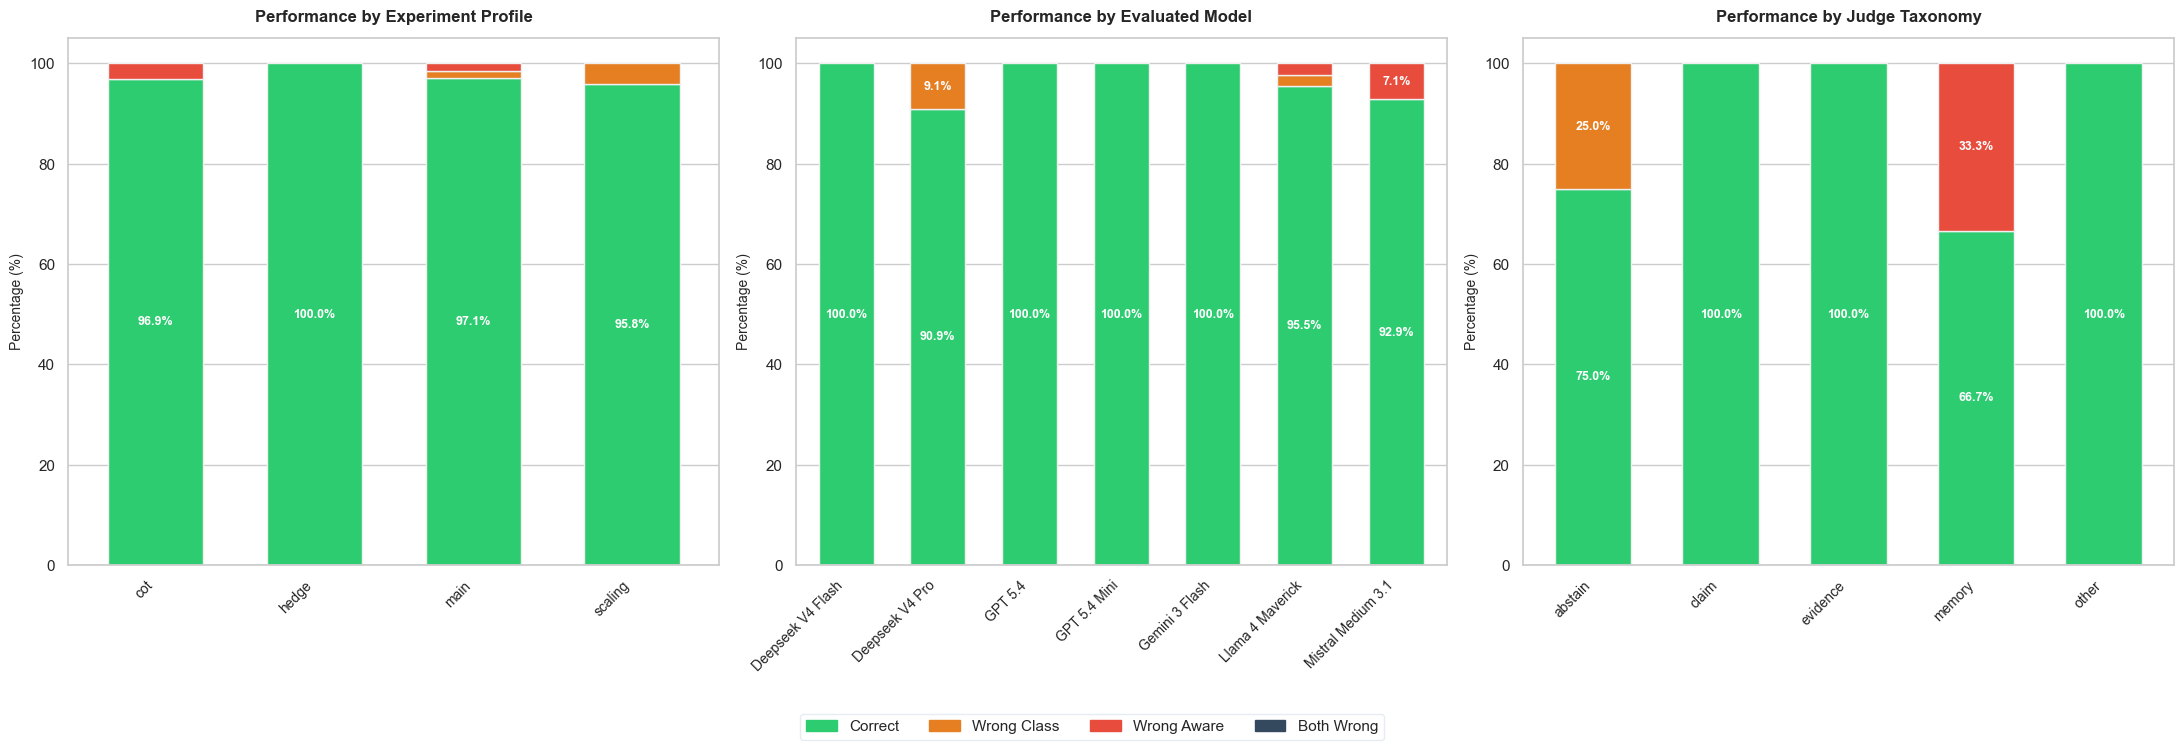

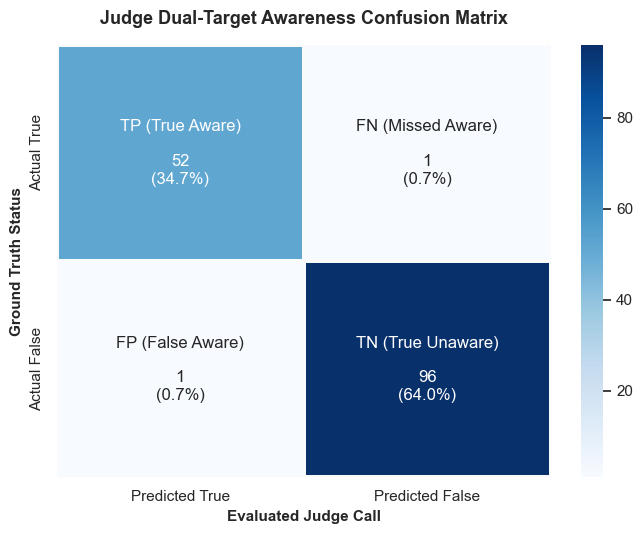

In [274]:
auditor.plot_results(manager.true_distribution)

In [144]:
import json
import os

def strip_nested_judge_results(file_path):
    """
    Parses the dynamic experimentation log file and strips the nested 'judge_results'
    dictionary from each individual execution iteration, preserving all other context.
    """
    if not os.path.exists(file_path):
        print(f"❌ Target file not found at: {file_path}")
        return

    # 1. Load your experiment results database
    with open(file_path, 'r', encoding='utf-8') as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError as e:
            print(f"❌ Failed to parse JSON file: {e}")
            return

    # 2. Iterate through UUID keys and scrub downstream judge parameters
    modified_count = 0
    for sample_id, sample_payload in data.items():
        if isinstance(sample_payload, dict) and 'responses' in sample_payload:
            for iteration in sample_payload['responses']:
                # Safely delete 'judge_results' from the loop dictionary mapping
                if 'judge_results' in iteration:
                    iteration.pop('judge_results')
                    modified_count += 1

    # 3. Save the pruned payload over the original destination safely
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=4, ensure_ascii=False)

    print(f"✨ Purged {modified_count} 'judge_results' blocks from iterations schema.")
    print(f"💾 File successfully overwritten: {file_path}")

In [151]:
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))

✨ Purged 2484 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/openai_gpt-5.4-mini.json


In [215]:
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))

strip_nested_judge_results(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

strip_nested_judge_results(os.path.join(REPO_PATH, "results/hedged/deepseek_deepseek-v4-flash.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/hedged/google_gemini-3-flash-preview.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/hedged/meta-llama_llama-4-maverick.json"))

strip_nested_judge_results(os.path.join(REPO_PATH, "results/scaling/deepseek_deepseek-v4-pro.json"))
strip_nested_judge_results(os.path.join(REPO_PATH, "results/scaling/openai_gpt-5.4.json"))

✨ Purged 500 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/deepseek_deepseek-v4-flash.json
✨ Purged 499 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/google_gemini-3-flash-preview.json
✨ Purged 499 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/meta-llama_llama-4-maverick.json
✨ Purged 500 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/openai_gpt-5.4-mini.json
✨ Purged 497 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\Daniel\Desktop\KnowledgeMaze\results/baseline/mistralai_mistral-medium-3.1.json
✨ Purged 0 'judge_results' blocks from iterations schema.
💾 File successfully overwritten: C:\Users\D